<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1 & 2: Define the Network Structure and Specify the CPDs

In [15]:

!pip -q install pgmpy

import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

model = DiscreteBayesianNetwork([
    ('Smoking','Lung Disease'),
    ('Pollution','Lung Disease'),
    ('Lung Disease','Cough'),
    ('Lung Disease','X-ray Result'),
    ('Lung Disease','Fatigue')
])

print("Nodes:", list(model.nodes()))
print("Edges:", list(model.edges()))


Nodes: ['Smoking', 'Lung Disease', 'Pollution', 'Cough', 'X-ray Result', 'Fatigue']
Edges: [('Smoking', 'Lung Disease'), ('Lung Disease', 'Cough'), ('Lung Disease', 'X-ray Result'), ('Lung Disease', 'Fatigue'), ('Pollution', 'Lung Disease')]


In [16]:

s = TabularCPD('Smoking',2,[[0.7],[0.3]])
p = TabularCPD('Pollution',2,[[0.6],[0.4]])

l = TabularCPD('Lung Disease',2,
    [[0.99,0.90,0.80,0.50],
     [0.01,0.10,0.20,0.50]],
    evidence=['Smoking','Pollution'],
    evidence_card=[2,2])

c = TabularCPD('Cough',2,
    [[0.9,0.2],[0.1,0.8]],
    evidence=['Lung Disease'],evidence_card=[2])

x = TabularCPD('X-ray Result',2,
    [[0.95,0.15],[0.05,0.85]],
    evidence=['Lung Disease'],evidence_card=[2])

f = TabularCPD('Fatigue',2,
    [[0.8,0.3],[0.2,0.7]],
    evidence=['Lung Disease'],evidence_card=[2])

model.add_cpds(s,p,l,c,x,f)
print("All CPDs added successfully")


All CPDs added successfully


### Task 3: Validate the Model

In [17]:

print("Model Valid:",model.check_model())

for cpd in model.get_cpds():
    print("\n",cpd)


Model Valid: True

 +------------+-----+
| Smoking(0) | 0.7 |
+------------+-----+
| Smoking(1) | 0.3 |
+------------+-----+

 +--------------+-----+
| Pollution(0) | 0.6 |
+--------------+-----+
| Pollution(1) | 0.4 |
+--------------+-----+

 +-----------------+--------------+--------------+--------------+--------------+
| Smoking         | Smoking(0)   | Smoking(0)   | Smoking(1)   | Smoking(1)   |
+-----------------+--------------+--------------+--------------+--------------+
| Pollution       | Pollution(0) | Pollution(1) | Pollution(0) | Pollution(1) |
+-----------------+--------------+--------------+--------------+--------------+
| Lung Disease(0) | 0.99         | 0.9          | 0.8          | 0.5          |
+-----------------+--------------+--------------+--------------+--------------+
| Lung Disease(1) | 0.01         | 0.1          | 0.2          | 0.5          |
+-----------------+--------------+--------------+--------------+--------------+

 +--------------+-----------------+

### Task 4: Draw the Network with NetworkX

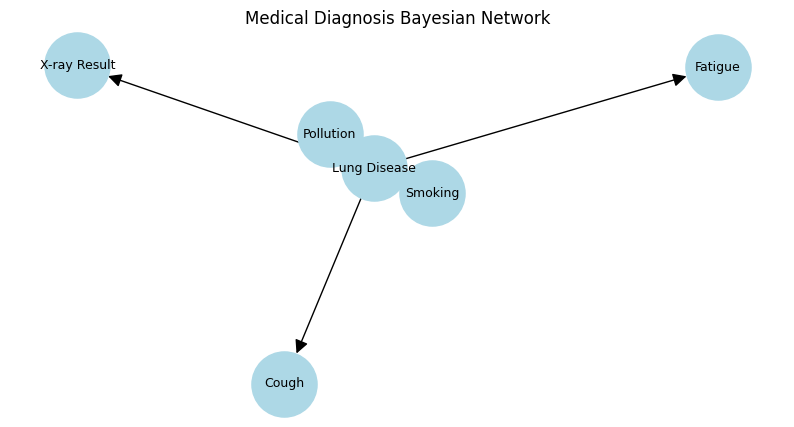

In [21]:

import networkx as nx
import matplotlib.pyplot as plt

# Convert Bayesian network to NetworkX graph
G = nx.DiGraph()
G.add_edges_from(model.edges())

plt.figure(figsize=(10, 5))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(G, pos, node_color='lightblue',
                       node_size=2200)

nx.draw_networkx_labels(G, pos, font_size=9)

nx.draw_networkx_edges(G, pos, arrows=True,
                       arrowsize=20, node_size=2200,
                       min_source_margin=15,
                       min_target_margin=15)

plt.title("Medical Diagnosis Bayesian Network")
plt.axis('off')
plt.show()


### Task 5: List Conditional Independencies and Active Trails

In [20]:

print("Conditional Independencies:")
for relation in model.get_independencies().get_assertions():
    print(relation)

print("\nActive Trails from Smoking:")
print(model.active_trail_nodes('Smoking'))

print("\nActive Trails from Smoking given Lung Disease:")
print(model.active_trail_nodes(
    'Smoking',observed=['Lung Disease']))

print("\nActive Trails from Cough given Lung Disease:")
print(model.active_trail_nodes(
    'Cough',observed=['Lung Disease']))


Conditional Independencies:
(Fatigue ⟂ Smoking | Lung Disease)
(Fatigue ⟂ X-ray Result | Lung Disease)
(Cough ⟂ Fatigue | Lung Disease)
(Pollution ⟂ X-ray Result | Lung Disease)
(Cough ⟂ X-ray Result | Lung Disease)
(Pollution ⟂ Smoking)
(Cough ⟂ Pollution | Lung Disease)
(Fatigue ⟂ Pollution | Lung Disease)
(Smoking ⟂ X-ray Result | Lung Disease)
(Cough ⟂ Smoking | Lung Disease)

Active Trails from Smoking:
{'Smoking': {'Fatigue', 'X-ray Result', 'Lung Disease', 'Smoking', 'Cough'}}

Active Trails from Smoking given Lung Disease:
{'Smoking': {'Pollution', 'Smoking'}}

Active Trails from Cough given Lung Disease:
{'Cough': {'Cough'}}
